In [37]:
import pandas as pd
import sys
from cleverminer import *

In [38]:
df = pd.read_csv("../data/processed/hotel_bookings_categorized.csv", dtype=str)
df.shape

(118558, 28)

In [39]:
cf = cleverminer(
    df=df,
    target="lead_time_cat",
    proc="CFMiner",
    quantifiers = {"S_Down":5, "Base":5000},
    cond = {
        "attributes":[
            {"name": "hotel", "type": "subset", "minlen":1, "maxlen":1},
            {"name": "has_children", "type": "subset", "minlen":1, "maxlen":1},
            {"name": "market_segment", "type": "subset", "minlen":1, "maxlen":1},
            {"name": "country_group", "type": "subset", "minlen":1, "maxlen":1},
            {"name": "distribution_channel", "type": "subset", "minlen":1, "maxlen":1},
            {"name": "customer_type", "type": "subset", "minlen":1, "maxlen":1},
        ],
        "minlen":1,
        "maxlen":3,
        "type":"con"
    }
)

Cleverminer version 1.2.8.
Starting data preparation ...
Automatically reordering numeric categories ...
Automatically reordering numeric categories ...done
Encoding columns into bit-form...
Encoding columns into bit-form...done
Data preparation finished.
Will go for  CFMiner
Starting to mine rules.
  0%|                                                    |Elapsed Time: 0:00:00
100%|####################################################|Elapsed Time: 0:00:00
Done. Total verifications : 228, rules 16, times: prep 0.39sec, processing 0.03sec


In [42]:
cf.print_rulelist()
cf.print_summary()
cf.print_rule(7)


List of rules:
RULEID BASE  S_UP  S_DOWN Condition
     1  5774     0     5 hotel(City Hotel) & has_children(0) & distribution_channel(Direct)
     2  5391     0     5 hotel(City Hotel) & market_segment(Direct) & customer_type(Transient)
     3  6678     0     5 hotel(City Hotel) & distribution_channel(Direct)
     4  5987     0     5 hotel(City Hotel) & distribution_channel(Direct) & customer_type(Transient)
     5  5527     0     5 hotel(Resort Hotel) & has_children(0) & market_segment(Direct)
     6  5183     0     5 has_children(0) & market_segment(Corporate)
     7 10683     0     5 has_children(0) & market_segment(Direct)
     8  9562     0     5 has_children(0) & market_segment(Direct) & customer_type(Transient)
     9  6250     0     5 has_children(0) & country_group(PRT) & distribution_channel(Direct)
    10 10502     0     5 has_children(0) & distribution_channel(Direct) & customer_type(Transient)
    11  5231     0     5 market_segment(Corporate)
    12  5728     0     5 ma

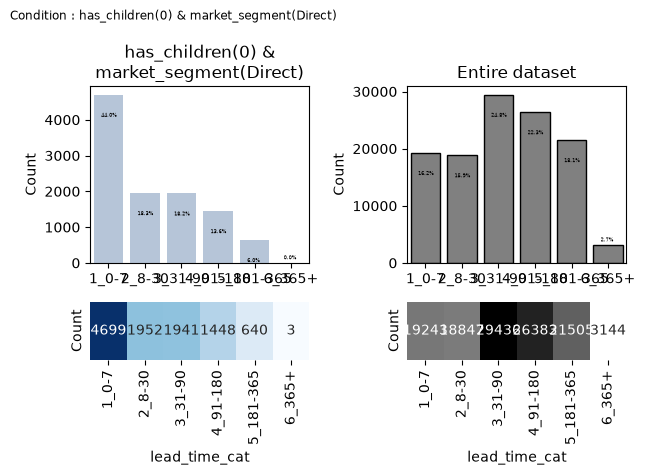

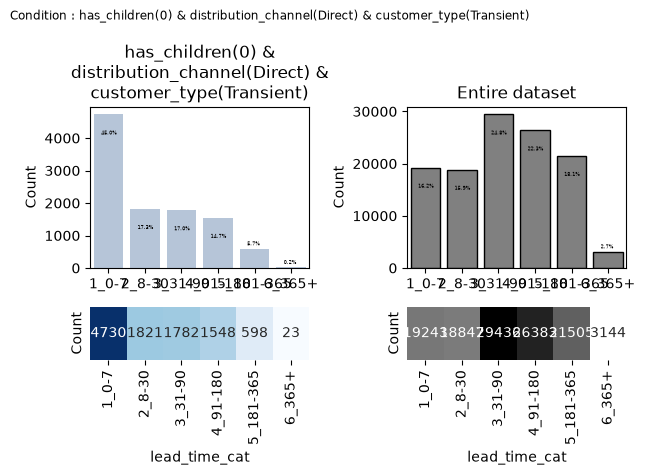

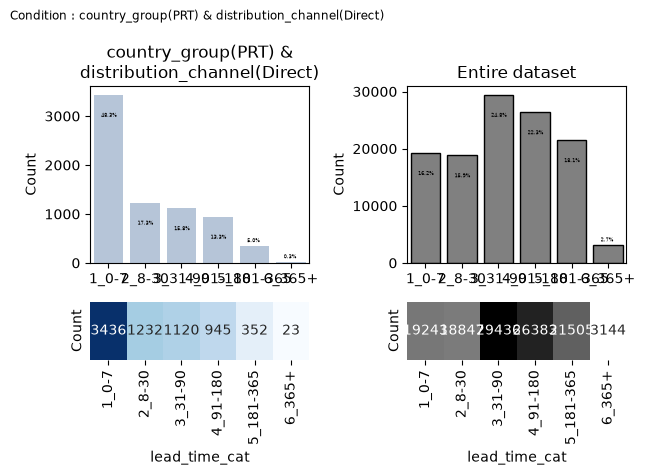

In [44]:
cf.draw_rule(7)
cf.draw_rule(10)
cf.draw_rule(15)